# Exploratory Data Analysis (EDA)

## 1. Introduction

Exploratory Data Analysis (EDA) is the process of examining, summarizing, and visualizing a dataset to understand its structure, identify patterns, detect unusual observations, and discover relationships between variables.

## 2. Project Objective

The objective of this analysis is to explore household electricity consumption data and identify meaningful patterns that can support better energy monitoring and consumption analysis.

## 3. Dataset Overview

The dataset contains minute-level household electricity measurements, including active power, reactive power, voltage, current intensity, and three sub-metering measurements.

## 4. EDA Activities

* Analyze the statistical distribution of numerical variables.
* Examine electricity consumption patterns and trends.
* Explore relationships between electrical measurements.
* Identify unusual observations and potential anomalies.
* Summarize findings that can be used in the dashboard.

## 5. Tools and Libraries

* Python
* Pandas
* NumPy
* Matplotlib
* Seaborn

## 6. Expected Outcome

The analysis will help identify important consumption patterns, understand relationships between electrical variables, and generate evidence-based insights for the Electricity Consumption Intelligence Dashboard.


In [2]:
import pandas as pd

df = pd.read_csv(
    "cleaned_electricity_data.csv",
    parse_dates=['Date', 'Datetime']
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (2049280, 17)


In [3]:
print("Dataset Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Columns:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Datetime', 'Hour', 'Day_of_Week', 'Day', 'Month', 'Year', 'Is_Weekend', 'Energy_kWh']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2049280 entries, 0 to 2049279
Data columns (total 17 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Date                   datetime64[us]
 1   Time                   str           
 2   Global_active_power    float64       
 3   Global_reactive_power  float64       
 4   Voltage                float64       
 5   Global_intensity       float64       
 6   Sub_metering_1         float64       
 7   Sub_metering_2         float64       
 8   Sub_metering_3         float64       
 9   Datetime               datetime64[us]
 10  Hour                   int64         
 11  Day_of_Week            str           
 12  Day            

## 1. Statistical Summary of the Dataset

In this section, we examine the statistical properties of the numerical variables using descriptive statistics.

The analysis includes:

* Mean: Average value.
* Standard deviation: How much the values vary.
* Minimum and maximum: The smallest and largest values.
* Quartiles: The distribution of values across the dataset.

**Objective:** Understand typical electricity consumption levels and identify variables that may require further investigation.


In [4]:
df.describe().round(3)

,Date,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime,Hour,Day,Month,Year,Energy_kWh
count,2049280,2049280.000,2049280.000,2049280.00,2049280.000,2049280.000,2049280.000,2049280.000,2049280,2049280.000,2049280.000,2049280.000,2049280.000,2049280.000
mean,2008-12-01 13:00:00.309182,1.092,0.124,240.84,4.628,1.122,1.299,6.458,2008-12-02 00:59:44.397739,11.504,15.712,6.454,2008.425,0.018
min,2006-12-16 00:00:00,0.076,0.000,223.20,0.200,0.000,0.000,0.000,2006-12-16 17:24:00,0.000,1.000,1.000,2006.000,0.001
25%,2007-12-10 00:00:00,0.308,0.048,238.99,1.400,0.000,0.000,0.000,2007-12-10 05:37:45,5.000,8.000,3.000,2007.000,0.005
50%,2008-11-30 00:00:00,0.602,0.100,241.01,2.600,0.000,0.000,1.000,2008-11-30 01:22:30,12.000,16.000,6.000,2008.000,0.010
75%,2009-11-23 00:00:00,1.528,0.194,242.89,6.400,0.000,1.000,17.000,2009-11-23 20:31:15,18.000,23.000,9.000,2009.000,0.025
max,2010-11-26 00:00:00,11.122,1.390,254.15,48.400,88.000,80.000,31.000,2010-11-26 21:02:00,23.000,31.000,12.000,2010.000,0.185
std,NaN,1.057,0.113,3.24,4.444,6.153,5.822,8.437,NaN,6.925,8.802,3.423,1.124,0.018


## 2. Missing Values Analysis

Missing values can affect statistical calculations, visualizations, and analytical conclusions.

In this section, we will calculate the number and percentage of missing values in each column to assess the completeness of the cleaned dataset.

**Objective:** Verify data completeness before proceeding with further exploratory analysis.


In [5]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Calculate missing-value percentage
missing_percentage = (missing_values / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage (%)': missing_percentage.round(3)
})

# Display the results
print("Missing Values Analysis:")
display(missing_summary)

Missing Values Analysis:


,Missing Values,Missing Percentage (%)
Date,0,0.0
Time,0,0.0
Global_active_power,0,0.0
Global_reactive_power,0,0.0
Voltage,0,0.0
Global_intensity,0,0.0
Sub_metering_1,0,0.0
Sub_metering_2,0,0.0
Sub_metering_3,0,0.0
Datetime,0,0.0


## 3. Distribution of Electricity Consumption

Distribution analysis helps us understand how electricity consumption values are spread across the dataset.

We will examine Global Active Power to identify common consumption ranges, understand variation, and investigate whether the distribution is symmetrical or skewed.

**Objective:** Understand typical household power consumption and identify values that may require further investigation.


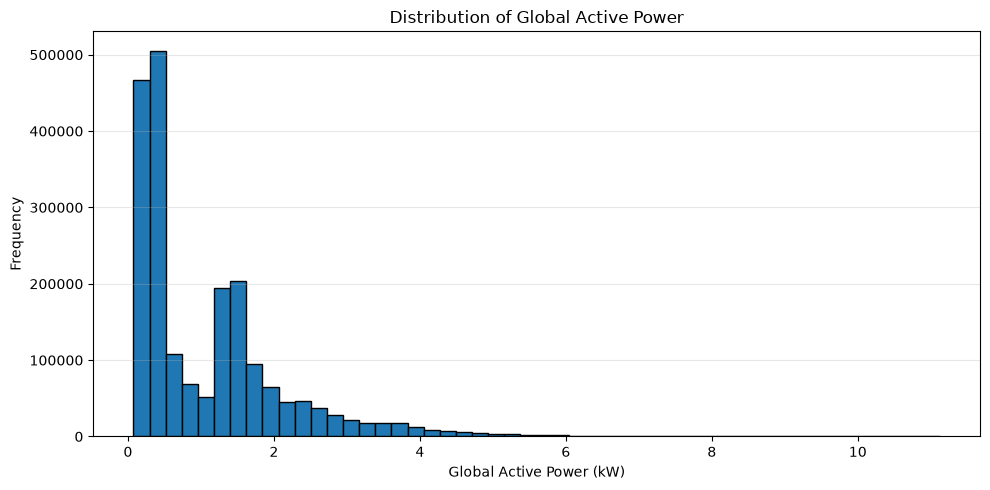

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df['Global_active_power'],
    bins=50,
    edgecolor='black'
)

plt.title('Distribution of Global Active Power')
plt.xlabel('Global Active Power (kW)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Finding

The histogram shows that Global Active Power readings are concentrated at lower values, with fewer observations at higher power levels. This suggests that the distribution is likely right-skewed.

**Practical significance:** Understanding this distribution can help distinguish typical household power usage from periods of unusually high demand. Further analysis is needed before classifying any observation as an anomaly.


In [7]:
skewness = df['Global_active_power'].skew()

print("Global Active Power Skewness:", round(skewness, 3))

Global Active Power Skewness: 1.786
